# PMAR demo

**PMAR** (Particle-based Modelling and Analysis for MARine Decision Support) drives [OpenDrift](https://opendrift.github.io/)
to simulate Lagrangian particle trajectories representing different tracers (generic, plastic,
chemical, oil, metal or larvae), then derives:

- **geospatial indicators** (density maps, Pressure Propagation Index or PPI)
- a **connectivity matrix** describing transition probabilities between grid cells,

from those trajectories.

This notebook walks through the core workflow in four steps:

1. **Basic run** — simulate trajectories with `get_trajectories`.
2. **Rasterizing pressure** — turn trajectories into gridded indicators with `get_indicators` and `get_ppi`.
3. **Connectivity analysis** — build a transition matrix and connectivity network with `get_Pij` and `get_network`.
4. **Markov-chain prediction** — propagate a distribution forward in time with `predict_with_CM`.

**Requirements**: run this notebook with the `opendrift` conda environment as the kernel
(it provides OpenDrift, PMAR's other geospatial dependencies, and has `PROJ_LIB` set up
correctly). You'll also need working Copernicus Marine credentials in `~/.netrc` — the
first run streams a couple of days of Mediterranean current data; after that, PMAR's
on-disk cache makes re-running this notebook instant and fully offline.

In [1]:
from shapely.geometry import box
import geopandas as gpd
import matplotlib.pyplot as plt

from pmar.pmar import PMAR
from pmar import plotting

# Small area in the Northern Adriatic Sea, and a single grid resolution, used
# throughout this notebook. Keeping one resolution everywhere means every raster
# we compute lives on exactly the same grid as the connectivity matrix, so they can be
# fed into each other directly with no resampling.
study_area = [12, 43.5, 16, 45.8]  # [xmin, ymin, xmax, ymax]
res = 0.2

## 1. Basic run: `get_trajectories`

A `PMAR` instance is tied to a spatial domain (one of `'global'`, `'med'`, `'black sea'`,
`'baltic'`) that determines which Copernicus datasets (currents, wind, bathymetry, ...)
are used to force the simulation. All outputs (cached trajectories, rasters, figures) are
written under `basedir`.

`get_trajectories` takes:

- `pnum` — number of particles to seed.
- `start_time` — simulation start date, as an ISO `'YYYY-MM-DD'` string.
- `duration_days` — length of the simulation.
- `seed_within_bounds` — `[xmin, ymin, xmax, ymax]` box to seed particles within (as an
  alternative to `seeding_shapefile`, for seeding from an arbitrary polygon/point/line
  shapefile instead of a rectangle).

We keep `pnum` and `duration_days` small here so the demo runs quickly.

2026-10-05 14:53:29,858 INFO    pmar:231: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>
2026-10-05 14:53:29,875 INFO    pmar:474: created seeding_shapefile with bounds [12, 43.5, 16, 45.8]
2026-10-05 14:53:29,878 INFO    pmar:483: particle_path exists = False, pmar_demo_output/cachedir/229a0f647fcb3a25a47469294e6a73bc.nc
2026-10-05 14:53:30,425 INFO    pmar:583: adding readers...
INFO - 2026-10-05T14:53:30Z - Selected dataset version: "202511"
INFO - 2026-10-05T14:53:30Z - Selected dataset part: "default"
INFO - 2026-10-05T14:53:34Z - Selected dataset version: "202211"
INFO - 2026-10-05T14:53:34Z - Selected dataset part: "default"
INFO - 2026-10-05T14:53:38Z - Selected dataset version: "202211"
INFO - 2026-10-05T14:53:38Z - Selected dataset part: "bathy"
INFO - 2026-10-05T14:53:39Z - Selected dataset version: "202511"
INFO - 2026-10-05T14:53:39Z - Selected dataset part: "default"
INFO - 2026-10-05T14:53:42Z - Selected dataset versi

string


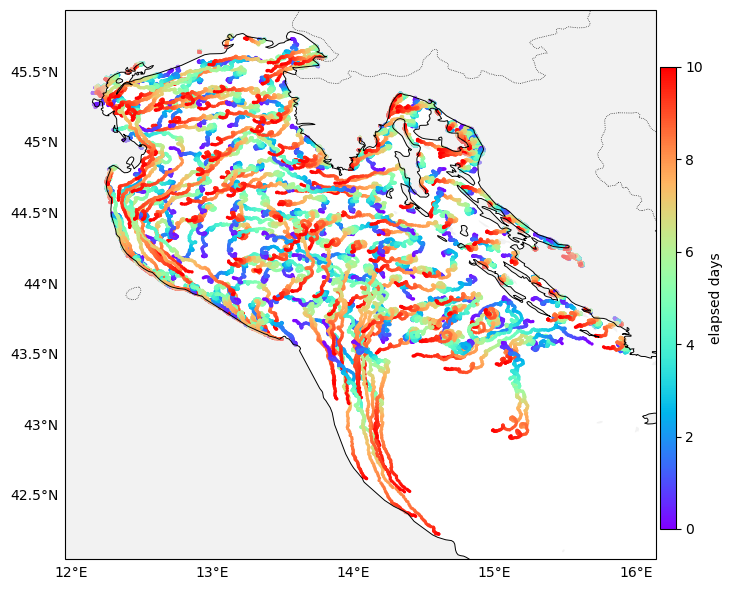

In [7]:
p = PMAR('med', basedir='pmar_demo_output', loglevel=20)
p.study_area = study_area  # reused by several methods below

p.get_trajectories(
    pnum=300,
    start_time='2021-06-01',
    duration_days=10,
    seed_within_bounds=study_area,
)

p.plot_trajectories(c='age', s=2)

## 2. Rasterizing pressure: `get_indicators` and `get_ppi`

Trajectories can be turned into gridded rasters in two complementary ways, both stored
together in `p.output`:

- **`get_indicators`** bins the raw (unweighted) particle positions over time into
  summary rasters: `SUM` (total visits per cell), `MAX` (peak concentration), and a
  quantile (`Q90` by default). This answers "where did particles actually go?".
- **`get_ppi`** computes the *Potential Pressure Index*: each particle is weighted by
  the intensity of a human-activity ("use") layer at its *starting* position, so the
  resulting raster answers "how much pressure, originating from this activity, reaches
  each cell?". It needs a `use` layer — a GeoDataFrame or raster with a single value
  column representing activity intensity (e.g. a platform's daily emission rate).

We call `get_indicators` first, before any weights exist, so `SUM`/`MAX`/`Q90` reflect
plain particle density; `get_ppi` then adds a `ppi` layer on top using a synthetic
small "demo source" area (stand in for a real layer such as AIS density, aquaculture
concessions, or platform locations).

Only particles that *start* inside the source area ever carry nonzero weight, so with
only `pnum=300` particles spread over the whole study area, just a handful actually
originate there — the resulting PPI map is correspondingly sparse. A real analysis would
increase `pnum` (or seed more densely near the activity of interest) for a smoother
estimate; we keep it small here to keep the demo fast.

2026-10-05 14:52:30,629 INFO    pmar:1119: ppi_exists = True, pmar_demo_output/ppi-demo_source/7c5882e4a3f106910e506e71d50b4e08.tif


3 / 300 particles started inside the demo source


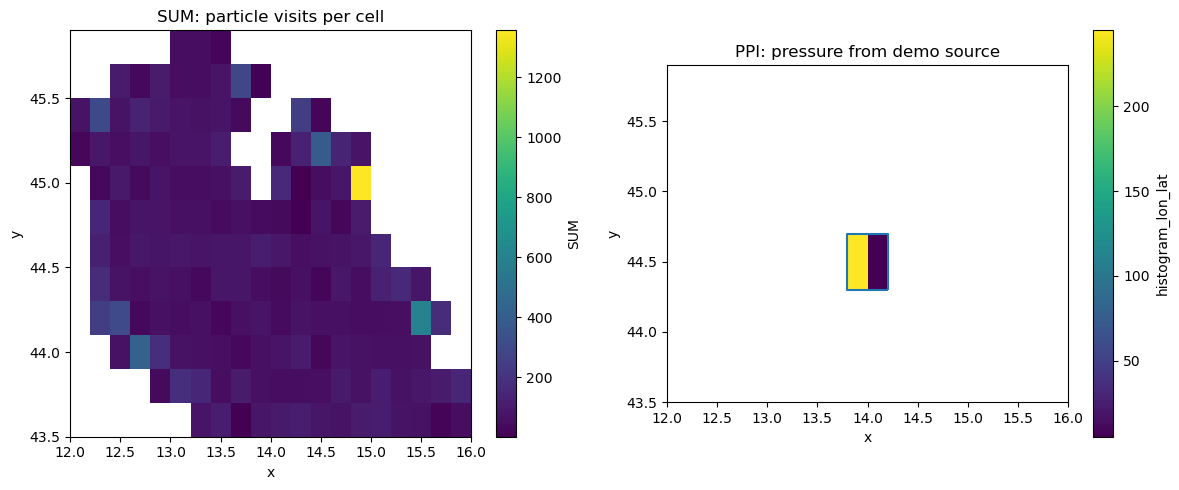

In [5]:
p.get_indicators(res=res, study_area=study_area)

# Synthetic "use" layer: a small hypothetical pressure source area, e.g. an offshore
# platform field emitting 1000 units/day, near the centre of the study area.
use = gpd.GeoDataFrame(
    {'value': [1000]},
    geometry=[box(13.8, 44.3, 14.2, 44.7)],
    crs='epsg:4326',
)

p.get_ppi(res=res, study_area=study_area, use=use, use_label='demo_source')

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
p.output['SUM'].where(p.output['SUM'] > 0).plot(ax=axs[0])
axs[0].set_title('SUM: particle visits per cell')
p.output['ppi'].where(p.output['ppi'] > 0).plot(ax=axs[1])
axs[1].set_title('PPI: pressure from demo source')
plt.tight_layout()

start_points = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(p.ds.isel(time=0).lon, p.ds.isel(time=0).lat), crs='epsg:4326',
)

use.boundary.plot(ax=axs[1])

n_inside = int(start_points.within(use.geometry.iloc[0]).sum())
print(f"{n_inside} / {p.ds.sizes['trajectory']} particles started inside the demo source")

## 3. Connectivity analysis: `get_Pij` and `get_network`

`get_Pij` turns particle transitions into a Markov **transition matrix**: entry `(i, j)`
is the probability that a particle starting in cell `i` at `t=0` ends up in cell `j` at
timestep `t`. We reuse the same `res`/`study_area` as above, so the resulting grid of
cells matches the rasters from section 2 exactly — useful later when we feed one of those
rasters into the Markov prediction in section 4.

> **Note:** `get_Pij` also accepts a `buffer` distance, which adds an absorbing
> "outside the tracked domain" cell — useful when the study area has open boundaries and
> you want particles that leave it to be treated as permanently gone rather than
> producing row sums below 1. Not used here, to keep the demo simple.

`get_network` turns the same matrix into a directed `networkx` graph, which we can then
draw. Cell boundaries (from `node_shapes`) give the plot spatial context even without a
full coastline basemap (`show_map=True` currently errors here when combined with the
default weight-based edge colorbar, due to a cartopy/matplotlib axes incompatibility in
`_plot_network` — using `show_map=False` avoids it). With this many cells we skip
`node_names` (per-node text labels) to keep the plot legible — labelling is more useful
on a much smaller network, e.g. `p.get_network(node_names=p.cm_grid['bin_n'].to_dict())`.

(<Figure size 700x700 with 2 Axes>, <Axes: >)

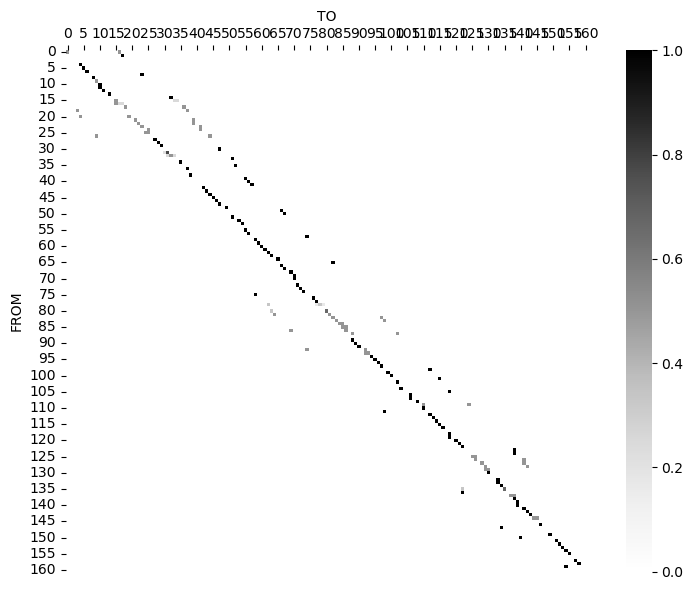

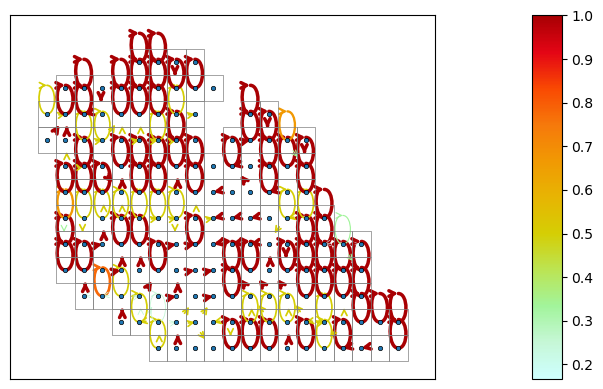

In [6]:
p.get_Pij(res=res, study_area=study_area, t=-1)
p.plot_CM()

G = p.get_network()
plotting._plot_network(
    G,
    node_shapes=p.cm_grid,
    show_map=False,
    node_size=10,
    rescale_edge=0.05,  # most cells retain >90% of their probability mass (short transit
                         # time relative to cell size), so without heavy downscaling edges
                         # dominate the plot
)

## 4. Markov-chain prediction: `predict_with_CM`

Given a starting distribution (occupancy/probability per cell) and the transition matrix
`CM`, `predict_with_CM` propagates it forward `k` Markov steps: `v -> v @ CM^k`. Each step
corresponds to the same `t` used when the matrix was built (here, the full 2-day
transition from the basic run).

We reuse the `SUM` raster from section 2 as the starting distribution. `predict_with_CM`
reprojects its input onto whichever grid is currently set on `p.grid` — since we've used
the same `res`/`study_area` throughout, that's the same grid `SUM` was already computed
on, so this reprojection is effectively a no-op (important: feeding in a raster from a
*different* resolution than the connectivity matrix would silently distort results, since
reprojecting an additive quantity like a particle count onto a coarser grid via
nearest-neighbour resampling does not sum the finer cells it replaces).

2026-10-05 14:40:16,402 WARNING pmar:1637: initial_condition and CM dimensions do not match


(161,)
(161,)
13061.555555555555
Starting mass: 14620.0
Predicted mass: 13061.555555555555 (may be <= starting mass: some probability can leak outside the tracked domain)


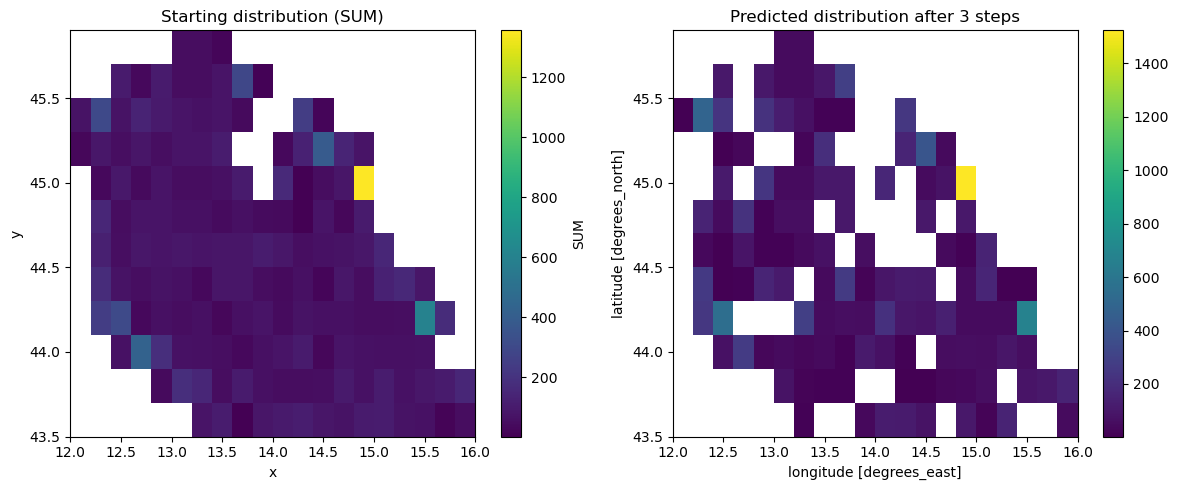

In [5]:
pred = p.predict_with_CM(p.output['SUM'], k=3)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
p.output['SUM'].where(p.output['SUM'] > 0).plot(ax=axs[0])
axs[0].set_title('Starting distribution (SUM)')
pred.where(pred > 0).plot(ax=axs[1])
axs[1].set_title('Predicted distribution after 3 steps')
plt.tight_layout()

print('Starting mass:', float(p.output['SUM'].sum()))
print('Predicted mass:', float(pred.sum()), '(may be <= starting mass: some probability can leak outside the tracked domain)')

## Where to go next

This notebook covered the core single-seeding workflow. A few other things PMAR can do:

- **Other pressure types**: pass `pressure='plastic'|'chemical'|'oil'|'metal'|'larvae'`
  to `PMAR(...)` instead of the default `'generic'` to use OpenDrift's specialized
  modules (e.g. `chemical_compound=` for `'chemical'`/`'metal'`).
- **Repeated seedings**: `PMARmulti` runs multiple seedings (e.g. at different start
  times) and averages results across them — useful for building a connectivity matrix
  that isn't tied to a single release date.
- **Dispersal distance**: `p.dispersal_distance()` computes the probability-weighted
  mean distance travelled from each cell, directly from the connectivity matrix.
- **`PMAR.run(...)`** bundles `get_trajectories` + `get_ppi` + `get_indicators` into a
  single call, for when you don't need the intermediate steps shown here.